# ==============================================================================
# Dataset analysis
# ==============================================================================

# Bloc A Titre et imports
## 1. Loading and inspecting the AI4I 2020 dataset
Objective: Load the dataset, inspect data types, check for missing values,
and identify columns that could lead to data leakage

### Importing libraries

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Visual configuration of charts
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

# Creating the folder to save the report images
os.makedirs("../reports/figure", exist_ok=True)

# Loading the CSV file
df = pd.read_csv("../Data/ai4i2020.csv")

print(f"Dataset dimensions : {df.shape[0]} observations, {df.shape[1]} colonnes.")
print(f"Total number of missing values: {df.isnull().sum().sum()}")

Dataset dimensions : 10000 observations, 14 colonnes.
Total number of missing values: 0


### INITIAL INSPECTION AND DATA STRUCTURE

In [3]:
# Displaying the first 5 lines
print("--- First 5 lines ---")
print(df.head())

# Random sample of 3 rows
print("\n--- Random sample of 3 rows ---")
print(df.sample(3, random_state=42))

# Technical structure (data types and non-null values)
print("\n--- Summary of data types and missing values ---")
df.info()

# 5. Statistiques de base sur chaque capteur
print("\n--- Descriptive statistics ---")
print(df.describe().T[['mean', 'std', 'min', '50%', 'max']])

--- First 5 lines ---
   UDI Product ID Type  Air temperature [K]  Process temperature [K]  \
0    1     M14860    M                298.1                    308.6   
1    2     L47181    L                298.2                    308.7   
2    3     L47182    L                298.1                    308.5   
3    4     L47183    L                298.2                    308.6   
4    5     L47184    L                298.2                    308.7   

   Rotational speed [rpm]  Torque [Nm]  Tool wear [min]  Machine failure  TWF  \
0                    1551         42.8                0                0    0   
1                    1408         46.3                3                0    0   
2                    1498         49.4                5                0    0   
3                    1433         39.5                7                0    0   
4                    1408         40.0                9                0    0   

   HDF  PWF  OSF  RNF  
0    0    0    0    0  
1    0    

# Block B — Cleaning and removal of data leakage
## Removing unusable columns and neutralizing data leakage
- `UDI` and `Product ID` are arbitrary identifiers with no physical connection to tool wear.
- The columns `TWF`, `HDF`, `PWF`, `OSF`, and `RNF` describe failure modes *ex post* (after the fact).
  Retaining them in X would create a critical data leak regarding the target variable, `Machine failure`.

In [4]:
# List of leakage columns and identifiers
colonnes_a_supprimer = ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']

# Separation of raw predictive variables (X_raw) and the target (y)
y = df['Machine failure']
X_raw = df.drop(columns=colonnes_a_supprimer + ['Machine failure'])

print("Explanatory variables selected for the analysis :")
print(X_raw.columns.tolist())

Explanatory variables selected for the analysis :
['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


# Block C — Target Visualization: Highlighting Class Imbalance
## Analysis of the Target Class Distribution
Checking the proportion of actual failures versus normal operation.

C:\Users\DELL\AppData\Local\Temp\ipykernel_6224\2997344009.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette=['#2b5c8f', '#d9534f'], ax=ax)
C:\Users\DELL\AppData\Local\Temp\ipykernel_6224\2997344009.py:9: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Normal (0)', 'Failure (1)'])


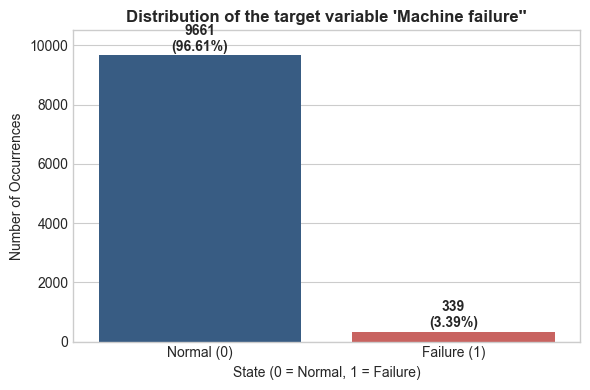

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
counts = y.value_counts()
proportions = y.value_counts(normalize=True) * 100

sns.barplot(x=counts.index, y=counts.values, palette=['#2b5c8f', '#d9534f'], ax=ax)
ax.set_title("Distribution of the target variable 'Machine failure''", fontsize=12, fontweight='bold')
ax.set_xlabel("State (0 = Normal, 1 = Failure)")
ax.set_ylabel("Number of Occurrences")
ax.set_xticklabels(['Normal (0)', 'Failure (1)'])

# Adding percentages to the bars
for i, count in enumerate(counts):
    prop = proportions[i]
    ax.text(i, count + 150, f"{count}\n({prop:.2f}%)", ha='center', fontsize=10, fontweight='bold')

plt.ylim(0, 10500)
plt.tight_layout()

# Sauvegarde pour le rapport Word
plt.savefig("../reports/figure/distribution_cible.png", dpi=300)
plt.show()

# Block D — Visual comparison of sensors based on machine state
## Boxplots of physical sensors: Normal machine vs. Failed machine
Allows for the visual identification of sensors that drift significantly before or during a failure.


C:\Users\DELL\AppData\Local\Temp\ipykernel_6224\386211181.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df['Machine failure'], y=df[capteur], ax=axes[i], palette=['#6baed6', '#fb6a4a'])
C:\Users\DELL\AppData\Local\Temp\ipykernel_6224\386211181.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df['Machine failure'], y=df[capteur], ax=axes[i], palette=['#6baed6', '#fb6a4a'])
C:\Users\DELL\AppData\Local\Temp\ipykernel_6224\386211181.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df['Machine failure'], y=df[capteur], ax=axe

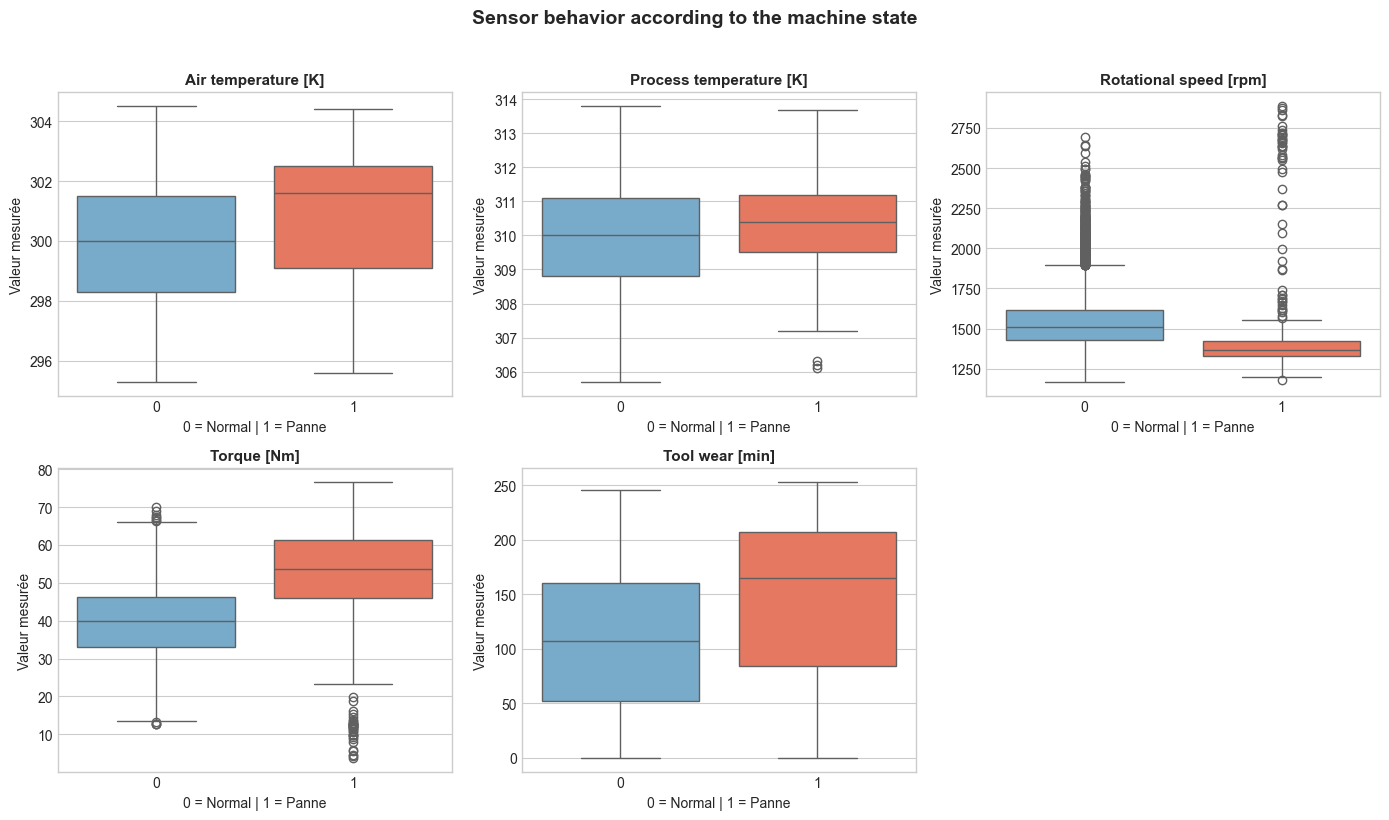

In [6]:
capteurs = [
    'Air temperature [K]', 
    'Process temperature [K]', 
    'Rotational speed [rpm]', 
    'Torque [Nm]', 
    'Tool wear [min]'
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.flatten()

for i, capteur in enumerate(capteurs):
    sns.boxplot(x=df['Machine failure'], y=df[capteur], ax=axes[i], palette=['#6baed6', '#fb6a4a'])
    axes[i].set_title(capteur, fontsize=11, fontweight='bold')
    axes[i].set_xlabel("0 = Normal | 1 = Panne")
    axes[i].set_ylabel("Valeur mesurée")

# Remove the 6th empty subgraph
fig.delaxes(axes[5])

plt.suptitle("Sensor behavior according to the machine state", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()

# Save for the Word report
plt.savefig("../reports/figure/boxplots_capteurs.png", dpi=300)
plt.show()

# ==============================================================================
# FEATURE ENGINEERING & SÉLECTION DES VARIABLES
# ==============================================================================

In [7]:
# Temperature differential (Heat dissipation)
df['Temp_diff'] = df['Process temperature [K]'] - df['Air temperature [K]']

# 2. Mechanical power in Watts (P = Torque * Angular velocity)
df['Power_W'] = df['Torque [Nm]'] * (df['Rotational speed [rpm]'] * (2 * np.pi / 60))

# 3. Cumulative mechanical stress (Torque * Tool wear   )
df['Overstrain'] = df['Torque [Nm]'] * df['Tool wear [min]']

# Ordinal encoding of the qualitative variable 'Type'
df['Type_encoded'] = df['Type'].map({'L': 0, 'M': 1, 'H': 2})

# 5. Definition of the selected explanatory variables (X)
features = [
    'Type_encoded',
    'Air temperature [K]',
    'Process temperature [K]',
    'Rotational speed [rpm]',
    'Torque [Nm]',
    'Tool wear [min]',
    'Temp_diff',
    'Power_W',
    'Overstrain'
]

X = df[features]
y = df['Machine failure']

# Verification of the result
print(f"Matrice des caractéristiques X : {X.shape[0]} lignes, {X.shape[1]} variables.")
print(f"Vecteur cible y : {y.shape[0]} étiquettes.")
print("\nAperçu des 3 premières lignes des variables créées :")
print(X[['Temp_diff', 'Power_W', 'Overstrain', 'Type_encoded']].head(3))

Matrice des caractéristiques X : 10000 lignes, 9 variables.
Vecteur cible y : 10000 étiquettes.

Aperçu des 3 premières lignes des variables créées :
   Temp_diff      Power_W  Overstrain  Type_encoded
0       10.5  6951.590560         0.0             1
1       10.5  6826.722724       138.9             0
2       10.4  7749.387543       247.0             0


# ==============================================================================
# STRATIFIED SEGMENTATION AND SCALING
# ==============================================================================

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# 80% training / 20% test split with stratification on the target variable
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size=0.20, 
    random_state=42, 
    stratify=y
)

# Verification of the conservation of the failure ratio
print(f"Dimensions Train : {X_train.shape[0]} lines | Failures : {y_train.sum()} ({y_train.mean()*100:.2f}%)")
print(f"Dimensions Test  : {X_test.shape[0]} lines  | Failures : {y_test.sum()} ({y_test.mean()*100:.2f}%)")

# Initialization of the normalizer (centering and scaling)
scaler = StandardScaler()

# Fitting on the training set, then transforming both the training and test sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Conversion to a DataFrame to preserve column names (optional and clean)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

print("\nExample of normalized variables (mean ~ 0, standard deviation ~ 1) on the Training Set :")
print(X_train_scaled[['Power_W', 'Torque [Nm]', 'Temp_diff']].head(3).round(3))

Dimensions Train : 8000 lines | Failures : 271 (3.39%)
Dimensions Test  : 2000 lines  | Failures : 68 (3.40%)

Example of normalized variables (mean ~ 0, standard deviation ~ 1) on the Training Set :
      Power_W  Torque [Nm]  Temp_diff
4058    0.852        0.718     -1.101
1221    0.480        0.638      1.300
6895    0.184        0.559      0.600


# ==============================================================================
# MODEL TRAINING (Logistic Regression vs. Random Forest)
# ==============================================================================

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Initialization of Logistic Regression (Baseline)
model_lr = LogisticRegression(
    class_weight='balanced', 
    random_state=42, 
    max_iter=1000
)

# Training the Logistic Regression model on the training data
model_lr.fit(X_train_scaled, y_train)

# Predictions of the Logistic Regression on the test set
y_pred_lr = model_lr.predict(X_test_scaled)
y_prob_lr = model_lr.predict_proba(X_test_scaled)[:, 1]

# Initialization of the Random Forest
model_rf = RandomForestClassifier(
    n_estimators=100, 
    class_weight='balanced', 
    random_state=42, 
    n_jobs=-1
)

# Training the Random Forest on the training data
model_rf.fit(X_train_scaled, y_train)

# Predictions of the Random Forest on the test set  
y_pred_rf = model_rf.predict(X_test_scaled)
y_prob_rf = model_rf.predict_proba(X_test_scaled)[:, 1]

print("Training successfully completed for both models!")

Training successfully completed for both models!


# ==============================================================================
# COMPARATIVE EVALUATION, CONFUSION MATRICES & FEATURE IMPORTANCE
# ==============================================================================

--- COMPARATIVE TABLE OF PERFORMANCE METRICS (TEST SET) ---
                     Exactitude (Accuracy)  Précision  Rappel (Recall)  \
Logistic Regression                 0.8575     0.1780           0.8824   
Random Forest                       0.9900     0.9615           0.7353   

                     F1-Score  
Logistic Regression    0.2963  
Random Forest          0.8333  


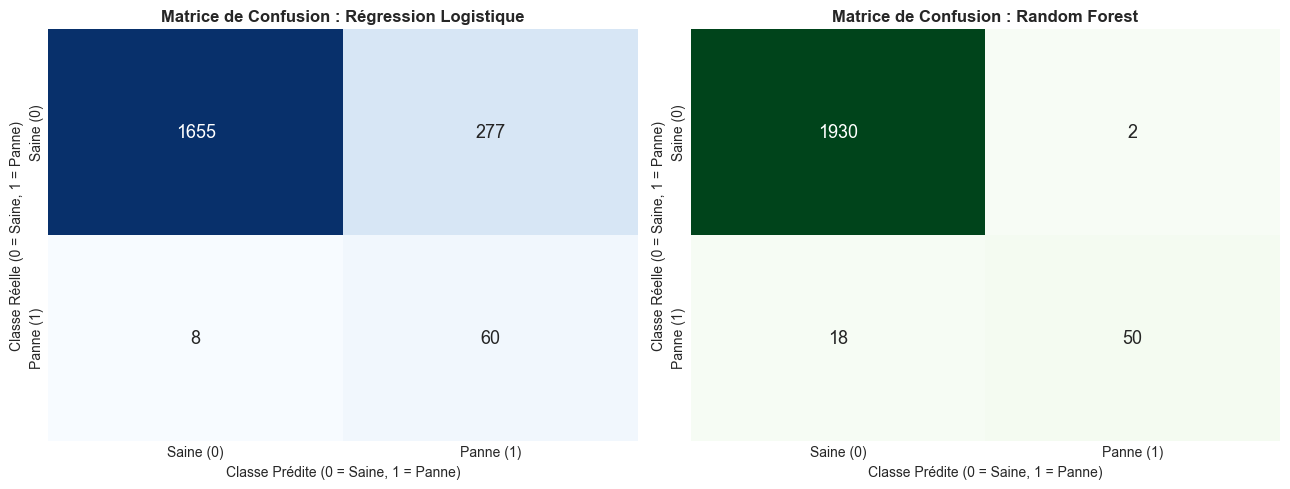

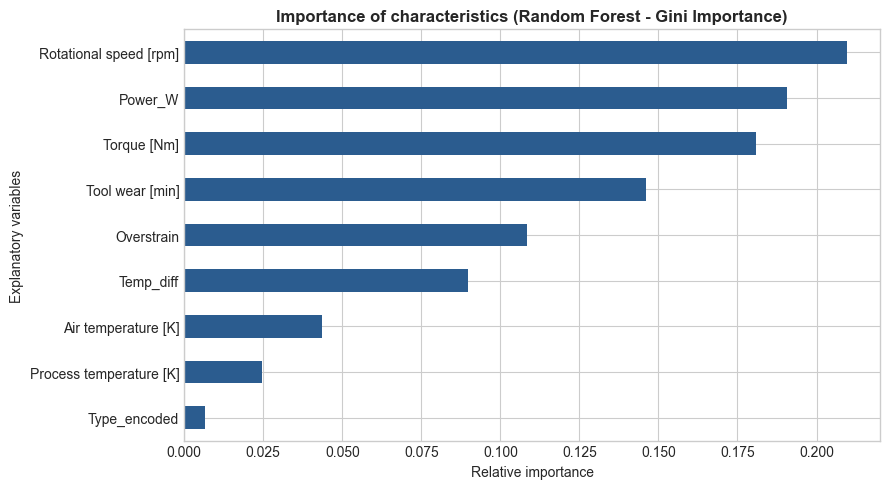

In [10]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Calculating metrics for Logistic Regression
metrics_lr = {
    'Exactitude (Accuracy)': accuracy_score(y_test, y_pred_lr),
    'Précision': precision_score(y_test, y_pred_lr),
    'Rappel (Recall)': recall_score(y_test, y_pred_lr),
    'F1-Score': f1_score(y_test, y_pred_lr)
}

# Calculating metrics for Random Forest
metrics_rf = {
    'Exactitude (Accuracy)': accuracy_score(y_test, y_pred_rf),
    'Précision': precision_score(y_test, y_pred_rf),
    'Rappel (Recall)': recall_score(y_test, y_pred_rf),
    'F1-Score': f1_score(y_test, y_pred_rf)
}

# Comparative summary table
df_comparatif = pd.DataFrame([metrics_lr, metrics_rf], index=['Logistic Regression', 'Random Forest'])
print("--- COMPARATIVE TABLE OF PERFORMANCE METRICS (TEST SET) ---")
print(df_comparatif.round(4))

# Plotting comparative confusion matrices
cm_lr = confusion_matrix(y_test, y_pred_lr)
cm_rf = confusion_matrix(y_test, y_pred_rf)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Matrice Régression Logistique
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0], annot_kws={'size': 13})
axes[0].set_title("Matrice de Confusion : Régression Logistique", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Classe Prédite (0 = Saine, 1 = Panne)")
axes[0].set_ylabel("Classe Réelle (0 = Saine, 1 = Panne)")
axes[0].set_xticklabels(['Saine (0)', 'Panne (1)'])
axes[0].set_yticklabels(['Saine (0)', 'Panne (1)'])

# Matrice Random Forest
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[1], annot_kws={'size': 13})
axes[1].set_title("Matrice de Confusion : Random Forest", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Classe Prédite (0 = Saine, 1 = Panne)")
axes[1].set_ylabel("Classe Réelle (0 = Saine, 1 = Panne)")
axes[1].set_xticklabels(['Saine (0)', 'Panne (1)'])
axes[1].set_yticklabels(['Saine (0)', 'Panne (1)'])

plt.tight_layout()
plt.savefig("../reports/figure/matrices_confusion.png", dpi=300)
plt.show()

# Variable importance according to Random Forest
importance = pd.Series(model_rf.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(9, 5))
importance.plot(kind='barh', color='#2b5c8f')
plt.title("Importance of characteristics (Random Forest - Gini Importance)", fontsize=12, fontweight='bold')
plt.xlabel("Relative importance")
plt.ylabel("Explanatory variables")
plt.tight_layout()
plt.savefig("../reports/figure/feature_importance.png", dpi=300)
plt.show()